# Library

In [1]:
import numpy as np
import pandas as pd
import scipy
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

# Quiz-List

 <li style="background-color:blue;color:white;border:solid gold 5px;padding:5px">
        Find the area to the left of the zscore 2.35.<br>
        Find the area to the left of the zscore -1.25.<br>
        Find the area to the left of the zscore 2.<br>
        Find the area between the zscore of 0.35 and 1.85.<br>
        Find the area between the zscore of -1.78 and -0.95.<br>
        Find the area between the zscore of -3.47 and 1.85.<br>
        Find the area to the right of the zscore 1.35.<br>
        Find the area to the right of the zscore -2.51.<br>
        Find the area to the left of the zscore -2.31 and the area to the right of the zscore 1.67.<br>
        Find the area to the left of the zscore -2 and the area to the right of the zscore of 1.<br>
        Find the area to the left of the zscore 1.31 and the area to the right of the zscore of 1.93.<br>
        Find the area to the left of the zscore -2.31 and the area to the right of the zscore of -1.67.<br>
        What z-value has an area of 0.0038 to its left?<br>
        What z-value has an area of 0.0212 to its left?<br>
        Find the z-value such that it's corresponding area is between -z and z is 0.99?<br>
        Find the z-value such that it's corresponding area is left of -z plus right of z is 0.0286 <br>
        What z-value represents the 95th percentile?<br></li>

# overview visualization

In [128]:
color_fill = []  #color list

for i in range(n_r*n_c):
    color_fill.append('#%06X' % np.random.randint(0, 0xFFFFFF))  # colors list 
colors_fill=np.array(color_fill).reshape(5,3)

In [134]:
n_r=5
n_c=3
size=10000000

np.random.seed(2)
x1=np.random.randn(size)
colorlists = []  #color list

for i in range(n_r*n_c):
    colorlists.append('#%06X' % np.random.randint(0, 0xFFFFFF))  # colors list 
colors=np.array(colorlists).reshape(5,3)

zscr_r=np.array([[ 2.35, 2, 1.85],
               [-0.95,1.85, 1.35],
               [ 1.67,1, 1.92],
               [-1.67,-2.669,-2.0],
               [2.575,2.188,1.6448]])
zscr_l=np.array([  [ -1.25, -4, 0.35],
                   [-1.78,-3.47, -2.51],
                   [ -2.31,-2, 1.31],
                   [-2.31,-4,-4.0],
                   [-2.575,-2.188,-4]])

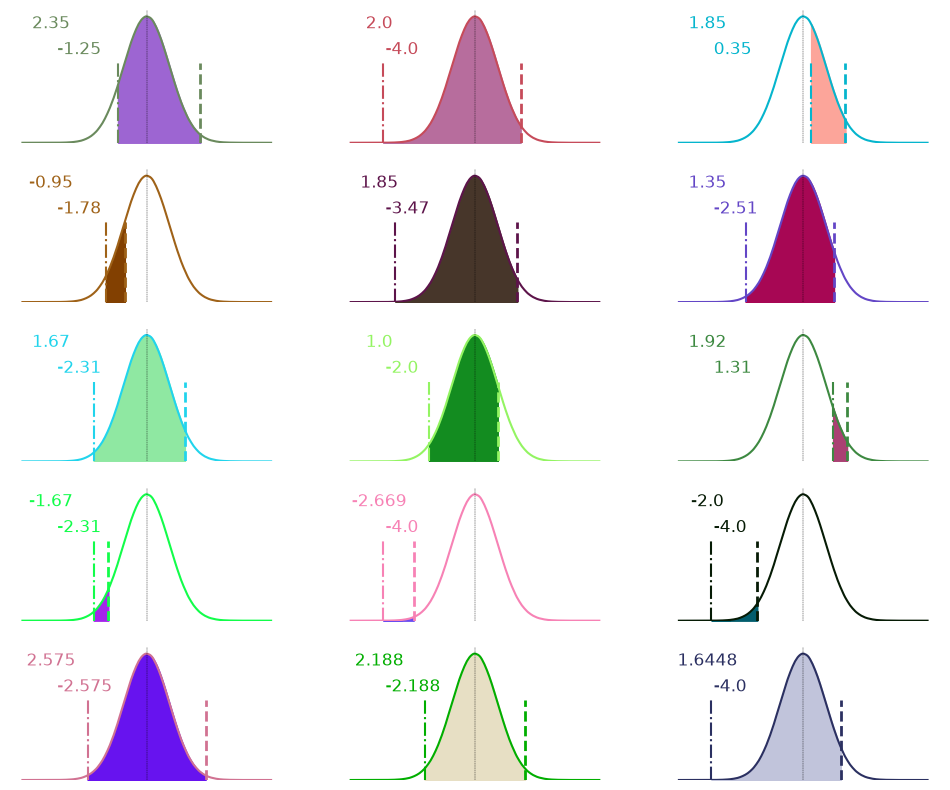

In [135]:
fig,ax=plt.subplots(n_r,n_c,figsize=(12,10))
for i in range(n_r):
    for j in range(n_c):
        ax[i,j].axis("off")
        ax[i,j].set_ylabel("")
        sns.kdeplot(x1,ax=ax[i,j],color=colors[i][j])
        ax[i,j].axvline(0,color="black",ls="--",lw=0.3)        
        ax[i,j].axvline(zscr_r[i][j],0,0.6,color=colors[i][j],ls="--",lw=2)
        ax[i,j].axvline(zscr_l[i][j],0,0.6,color=colors[i][j],ls="-.",lw=1.5)        
        ax[i,j].set_title("{}".format(zscr_r[i][j]),color=colors[i][j],x=0.15,y=0.8)
        ax[i,j].annotate("{}".format(zscr_l[i][j]),color=colors[i][j],xy=(-3.9,0.28),size=12)
        xfill1=np.linspace( zscr_l[i][j], zscr_r[i][j],100 )
        yfill1=stats.norm.pdf(xfill1)
        ax[i,j].fill_between(xfill1,yfill1,color=colors_fill[i][j])
plt.savefig("sdd.pdf")  
plt.show()

# Python Solutions 

## zscore to area|prob

### area to the left

In [2]:
# area to the left
left1=[2.35,-1.25,2]
l_ans=[]
for i in left1:
    l_ans.append(np.around(stats.norm.cdf(i),4))
l_ans

[np.float64(0.9906), np.float64(0.1056), np.float64(0.9772)]

### area to the right

In [3]:
# area to the right
rigt1=[1.35,-2.51]
r_ans=[]
for i in rigt1:
    r_ans.append(np.around(stats.norm.sf(i),4))
r_ans

[np.float64(0.0885), np.float64(0.994)]

### area in betwen subtraction 

In [4]:
# area in betwen subtraction 
a_bet=np.array([[1.85,-0.95,1.85],[0.35,-1.78,-3.47]]) # larger value in a the first  inner list
n_r1=np.arange(a_bet.shape[0])

arb_anw=[]

for j in range(a_bet.shape[1]):
        arb_anw.append(np.around(stats.norm.cdf(a_bet[n_r1[0]][j]) - stats.norm.cdf(a_bet[n_r1[1]][j]) ,5))
arb_anw

[np.float64(0.33101), np.float64(0.13352), np.float64(0.96758)]

### areas on both tails addition 

In [5]:
a_tails=np.array([[-2.31,-2,1.31,-2.31],[1.67,1,1.93,-1.67]])
n_r2=np.arange(a_bet.shape[0])
art_anw=[]
for i in range(a_tails.shape[1]):
    art_anw.append(np.around( stats.norm.cdf(a_tails[n_r2[0]][i])+stats.norm.sf(a_tails[n_r2[1]][i]),5))
art_anw

[np.float64(0.0579),
 np.float64(0.18141),
 np.float64(0.93171),
 np.float64(0.96298)]

## area|prob to zscore

In [6]:
# prob to zscore
prb1=[0.0038,0.0212,(1-0.99)/2,0.0286/2,0.95]
zsc=[]
for i in prb1:
    zsc.append(np.around(stats.norm.ppf(i),5))
zsc

[np.float64(-2.66934),
 np.float64(-2.02957),
 np.float64(-2.57583),
 np.float64(-2.18896),
 np.float64(1.64485)]

## concatenate all results

In [7]:
all_ans=np.concat((l_ans,arb_anw,r_ans,art_anw,zsc))

## dataframe convsersion

In [8]:
df=pd.DataFrame(all_ans,columns=["Zscore|Prob"])
df.index.name="Quiz #"
df.columns.name="Answers"
df

Answers,Zscore|Prob
Quiz #,
0,0.99060
1,0.10560
2,0.97720
3,0.33101
4,0.13352
5,0.96758
6,0.08850
7,0.99400
8,0.05790


# Excel vs Python Results Comparison

In [9]:
df=pd.read_excel("zscoreprob.xlsx")
pd.set_option('display.max_colwidth', None)
df

,quiz,excel,python
0,Find the area to the left of the zscore 2.35.,0.9906,0.9906
1,Find the area to the left of the zscore -1.25.,0.1056,0.1056
2,Find the area to the left of the zscore 2.,0.9772,0.9772
3,Find the area between the zscore of 0.35 and 1.85.,0.3310,0.3310
4,Find the area between the zscore of -1.78 and -0.95.,0.1335,0.1335
5,Find the area between the zscore of -3.47 and 1.85.,0.9676,0.9676
6,Find the area to the right of the zscore 1.35.,0.0885,0.0885
7,Find the area to the right of the zscore -2.51.,0.9940,0.9940
8,Find the area to the left of the zscore -2.31 and the area to the right of the zscore 1.67.,0.0579,0.0579
9,Find the area to the left of the zscore -2 and the area to the right of the zscore of 1.,0.1814,0.1814
